# 01 — تحلیل اکتشافی داده‌ها (EDA)
## پروژه تخمین هزینه حمل Atramart

در این نوت‌بوک اولین مرحله یادگیری ماشین را تمرین می‌کنیم: شناخت دیتاست، قبل از آموزش مدل.

**هدف کسب‌وکار:** پیش‌بینی هزینه واقعی حمل (`real_cost`) تا مبلغی که از مشتری دریافت می‌شود (`shipping_cost`) به هزینه واقعی نزدیک‌تر باشد.

> این دیتاست مصنوعی است و برای تمرین کدنویسی و بررسی Pipeline ساخته شده؛ نتیجه مدل روی آن تضمین‌کننده عملکرد روی داده واقعی نیست.

### واژه‌های مهم
- **رکورد / ردیف (row):** اطلاعات یک سفارش.
- **ویژگی (feature):** اطلاعاتی که مدل برای پیش‌بینی استفاده می‌کند.
- **هدف (target):** چیزی که مدل باید پیش‌بینی کند؛ در پروژه ما `real_cost`.
- **EDA:** بررسی و شناخت داده با آمار و نمودار، قبل از مدل‌سازی.


## 1. وارد کردن کتابخانه‌ها

کتابخانه‌ها ابزارهای آماده‌ای هستند که به جای نوشتن همه چیز از صفر استفاده می‌کنیم.

- `pandas` برای خواندن و بررسی جدول‌ها
- `matplotlib` برای رسم نمودار
- `Path` برای ساخت مسیر فایل به شکل قابل‌اعتماد


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# این مسیر با ساختار پروژه‌ای که ساختیم هماهنگ است
DATA_PATH = Path("../data/raw/atramart_random_shipping_dataset.csv")

df = pd.read_csv(DATA_PATH, parse_dates=["shipping_date"])

print("دیتاست با موفقیت خوانده شد.")

دیتاست با موفقیت خوانده شد.


## 2. دیدن چند ردیف اول

`head()` چند ردیف ابتدایی را نشان می‌دهد. این کار کمک می‌کند شکل کلی داده را ببینیم.

در این مرحله فقط مشاهده می‌کنیم؛ هنوز چیزی را تغییر نمی‌دهیم.


In [2]:
df.head()

,order_id,weight,items_count,base_city,destination_city,destination_region,product_category,shipping_date,package_count,carrier_name,service_type,shipping_cost,real_cost
0,ATR-000001,1381,2,Tehran,Yazd,NaN,Computer Case,2025-01-24,1,Post,Special,187016,227872
1,ATR-000002,1644,4,Tehran,Yazd,NaN,Monitor,2025-05-14,1,Courier,Normal,183119,197091
2,ATR-000003,1345,8,Tehran,Tehran,North,Laptop,2025-09-11,2,Courier,Normal,161537,162420
3,ATR-000004,4924,1,Tehran,Tehran,South,Networking,2026-06-03,1,Courier,Express,173595,170093
4,ATR-000005,296,6,Tehran,Tabriz,NaN,Monitor,2026-05-04,2,Tipax,Normal,175357,217311


## 3. اندازه دیتاست

`shape` یک زوج عددی برمی‌گرداند:

`(تعداد ردیف‌ها, تعداد ستون‌ها)`

هر ردیف در این دیتاست نماینده یک سفارش است.


In [5]:
df.shape

(3000, 13)

## 4. نام و نوع ستون‌ها

نوع داده به Python می‌گوید با هر ستون چگونه رفتار کند.

- `int64`: عدد صحیح، مثل وزن بر حسب گرم
- `float64`: عدد اعشاری
- `object` یا `string`: متن یا دسته‌بندی
- `datetime64`: تاریخ و زمان

نکته: شناسه سفارش (`order_id`) متنی است، حتی اگر بخشی از آن عدد باشد؛ معنای عددی ندارد.


In [6]:
df.dtypes

order_id                         str
weight                         int64
items_count                    int64
base_city                        str
destination_city                 str
destination_region               str
product_category                 str
shipping_date         datetime64[us]
package_count                  int64
carrier_name                     str
service_type                     str
shipping_cost                  int64
real_cost                      int64
dtype: object

## 5. بررسی مقدارهای خالی

مقدار خالی یعنی برای یک سلول اطلاعاتی نداریم. در pandas معمولاً با `NaN` یا `None` دیده می‌شود.

`isna()` سلول‌های خالی را علامت می‌زند و `sum()` تعداد آن‌ها را در هر ستون می‌شمارد.


In [7]:
df.isna().sum()

order_id                 0
weight                   0
items_count              0
base_city                0
destination_city         0
destination_region    1957
product_category         0
shipping_date            0
package_count            0
carrier_name             0
service_type             0
shipping_cost            0
real_cost                0
dtype: int64

## 6. بررسی سفارش‌های تکراری

`duplicated()` ردیف‌هایی را پیدا می‌کند که تکراری هستند. چون `order_id` باید یکتا باشد، جداگانه آن را بررسی می‌کنیم.


In [9]:
print("ردیف‌های کاملاً تکراری:", df.duplicated().sum())
print("order_id تکراری:", df["order_id"].duplicated().sum())

ردیف‌های کاملاً تکراری: 0
order_id تکراری: 0


## 7. آمار ستون‌های عددی

`describe()` خلاصه‌ای از ستون‌های عددی می‌دهد:

- `count`: تعداد مقدارهای غیرخالی
- `mean`: میانگین
- `std`: انحراف معیار؛ میزان پراکندگی
- `min` و `max`: کمترین و بیشترین مقدار
- `25%`, `50%`, `75%`: چارک‌ها؛ `50%` همان میانه است

در این پروژه هزینه‌ها را با واحد ریال ذخیره کرده‌ایم. هنگام تفسیر اعداد حتماً واحد را در نظر بگیر.


In [12]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
weight,3000.0,1881.680667,150.0,751.75,1371.0,2293.0,37901.0,1886.168775
items_count,3000.0,4.476333,1.0,2.0,5.0,6.0,8.0,2.288636
shipping_date,3000,2025-06-07 23:10:04.800000,2024-01-01 00:00:00,2024-09-13 00:00:00,2025-06-11 00:00:00,2026-03-10 06:00:00,2026-11-22 00:00:00,NaN
package_count,3000.0,1.454667,1.0,1.0,1.0,2.0,3.0,0.554419
shipping_cost,3000.0,180693.480333,41336.0,137657.5,175152.5,215755.5,528356.0,60609.399524
real_cost,3000.0,196667.09,52978.0,151143.75,191488.5,236040.75,652521.0,64171.945012


## 8. تعداد مقادیر هر دسته

برای ستون‌هایی مثل شهر، شرکت حمل و دسته کالا، میانگین معنی خاصی ندارد. به جای آن تعداد هر دسته را بررسی می‌کنیم.


In [13]:
categorical_cols = [
    "base_city",
    "destination_city",
    "destination_region",
    "product_category",
    "carrier_name",
    "service_type",
]

for col in categorical_cols:
    print(f"\\n--- {col} ---")
    print(df[col].value_counts(dropna=False))

\n--- base_city ---
base_city
Tehran    3000
Name: count, dtype: int64
\n--- destination_city ---
destination_city
Tehran     1043
Isfahan     353
Mashhad     328
Rasht       281
Shiraz      274
Yazd        245
Tabriz      245
Ahvaz       231
Name: count, dtype: int64
\n--- destination_region ---
destination_region
NaN        1957
East        223
West        215
Central     210
North       204
South       191
Name: count, dtype: int64
\n--- product_category ---
product_category
Peripheral       614
Laptop           510
Monitor          475
Computer Case    429
Accessory        374
Networking       355
Printer          243
Name: count, dtype: int64
\n--- carrier_name ---
carrier_name
Post       1191
Tipax       830
Cargo       582
Courier     397
Name: count, dtype: int64
\n--- service_type ---
service_type
Normal     1820
Express     862
Special     318
Name: count, dtype: int64


## 9. توزیع وزن سفارش‌ها

هیستوگرام نشان می‌دهد مقدارهای یک ویژگی در چه بازه‌هایی بیشتر دیده می‌شوند.

هر ستون میله‌ای، تعداد سفارش‌های داخل یک بازه وزنی را نشان می‌دهد.


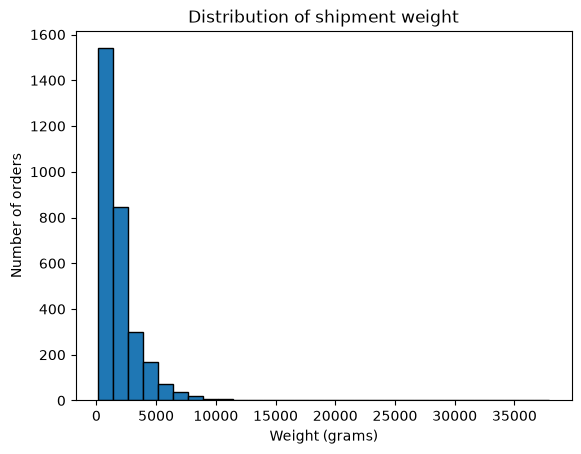

In [14]:
df["weight"].plot(kind="hist", bins=30, edgecolor="black")
plt.title("Distribution of shipment weight")
plt.xlabel("Weight (grams)")
plt.ylabel("Number of orders")
plt.show()

## 10. مقایسه هزینه دریافتی و واقعی

در نمودار زیر هر سفارش دو هزینه دارد:
- `shipping_cost`: پول دریافت‌شده از مشتری
- `real_cost`: پول پرداخت‌شده به شرکت حمل

اگر نقطه‌ای بالای خط برابری باشد، هزینه دریافتی بیشتر از هزینه واقعی است؛ اگر پایین خط باشد، هزینه دریافتی کمتر است.


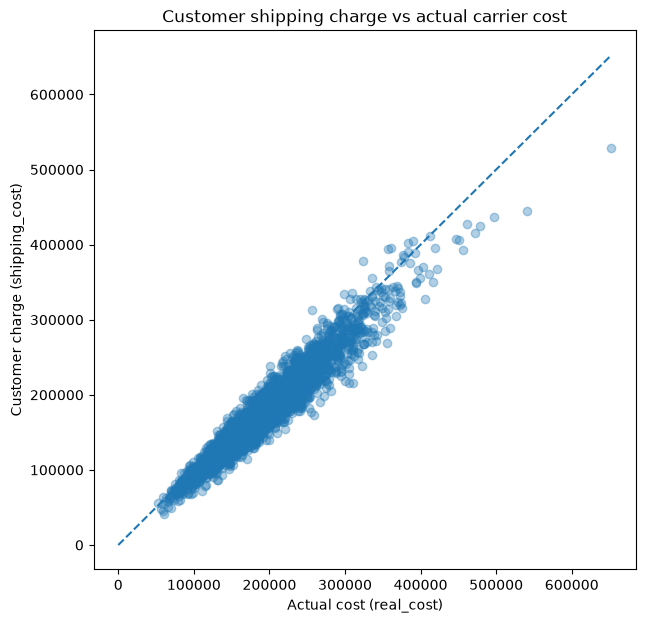

In [20]:
plt.figure(figsize=(7, 7))
plt.scatter(df["real_cost"], df["shipping_cost"], alpha=0.35)
max_value = max(df["real_cost"].max(), df["shipping_cost"].max())
plt.plot([0, max_value], [0, max_value], linestyle="--")
plt.title("Customer shipping charge vs actual carrier cost")
plt.xlabel("Actual cost (real_cost)")
plt.ylabel("Customer charge (shipping_cost)")
plt.show()

## 11. بررسی اختلاف سود/ضرر هزینه ارسال

برای هر سفارش اختلاف را حساب می‌کنیم:

`shipping_cost - real_cost`

- مثبت: مبلغ دریافتی بیشتر بوده (حاشیه مثبت)
- منفی: مبلغ دریافتی کمتر بوده (کسری هزینه)
- صفر: برابر بوده

این اختلاف فقط اختلاف هزینه ارسال است و سود کلی سفارش را نشان نمی‌دهد.


In [21]:
df["shipping_difference"] = df["shipping_cost"] - df["real_cost"]

print("تعداد سفارش‌های با مبلغ دریافتی کمتر:", (df["shipping_difference"] < 0).sum())
print("تعداد سفارش‌های با مبلغ دریافتی بیشتر:", (df["shipping_difference"] > 0).sum())
print("میانگین اختلاف:", round(df["shipping_difference"].mean()))
print("میانه اختلاف:", round(df["shipping_difference"].median()))

تعداد سفارش‌های با مبلغ دریافتی کمتر: 2488
تعداد سفارش‌های با مبلغ دریافتی بیشتر: 512
میانگین اختلاف: -15974
میانه اختلاف: -14467


## تمرین کوچک

1. با `df["destination_city"].value_counts()` ببین کدام شهر بیشترین سفارش را دارد.
2. با `df["real_cost"].mean()` میانگین هزینه واقعی را پیدا کن.
3. به نمودار هزینه‌ها نگاه کن: بیشتر سفارش‌ها زیر خط برابری هستند یا بالای آن؟
4. چرا `order_id` نباید به عنوان ویژگی مدل استفاده شود؟

**مرحله بعد:** پس از اینکه این نوت‌بوک را اجرا و نتایج را فهمیدیم، سراغ آماده‌سازی داده و تعریف دقیق ورودی‌ها و هدف مدل می‌رویم.


In [22]:
df["destination_city"].value_counts()

destination_city
Tehran     1043
Isfahan     353
Mashhad     328
Rasht       281
Shiraz      274
Yazd        245
Tabriz      245
Ahvaz       231
Name: count, dtype: int64

In [24]:
df["real_cost"].mean()

np.float64(196667.09)